# Monkey V1 LFP

A neural recording is observed as a single waveform, but its temporal
relationships can be represented as a trajectory in a reconstructed
state space. This tutorial uses a monkey V1 local field potential (LFP) recording
to connect two views of the same signal: an autoregressive model of
its local dynamics and the geometry of its delay coordinates.

The workflow moves from loading and processing a channel to fitting a
classical AR model, inspecting its prediction errors, and comparing
observed and reconstructed trajectories. Time-window, delay, and channel
comparisons then show which features of the geometry depend on the
chosen view. Black curves represent the processed recording; dark-red
curves represent the model reconstruction.

The aim is to understand **what the model reproduces and how to interpret
the resulting geometry**, not simply to maximize a prediction score.
A loop or torus-like appearance is a useful geometric observation,
but a three-dimensional picture alone does not determine topology or
count independent generators. These examples use a fitted linear AR
model; they do not require training DeepLagField.

## 1. Set Up the Notebook

Install the package with its `tutorials` dependencies as described in
[Installation](../installation.rst), then run the cells in order.
`neuralfieldmanifold` is imported as `nfm`. NumPy handles arrays,
Matplotlib displays the comparisons, and the shared plotting style
keeps figures consistent across the tutorial.

The complete analysis includes multiple recording channels, so it
requires the recording file(s) described below. The small bundled
samples used in [Getting Started](../getting_started.rst) are suitable
for learning the API but do not contain every channel needed here.
The website displays saved results; opening a page does not run the
analysis or require access to the recording.


In [1]:
import neuralfieldmanifold as nfm

In [2]:
import neuralfieldmanifold as nfm
import matplotlib.pyplot as plt
from pathlib import Path
import os
color_main, color_alt = "black", "darkred"
import numpy as np
import mne
import os
import pywt
import scipy.io as sio
from scipy import signal
from scipy.signal import hilbert
from matplotlib.ticker import ScalarFormatter
from statsmodels.tsa.stattools import acf
from scipy.ndimage import gaussian_filter1d






# capture future warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

nfm.plotting.set_style()

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg", "retina")


## 2. Assemble the Reconstruction Pipeline

The helper functions separate three tasks: preparing a signal, estimating
its dynamics, and comparing observed and reconstructed trajectories.
Signal processing is handled by `nfm.preprocessing`; the autoregressive
design matrix comes from `nfm.embedding.lag_matrix`; and
`nfm.models.AR` estimates the coefficients by ordinary least squares.

An autoregressive model of order $p$ predicts the next sample from the
previous $p$ samples:

$$\widehat{x}(t)=b+\sum_{i=1}^{p}a_i x(t-i).$$

The intercept $b$ accounts for a constant offset. The coefficients $a_i$
describe how recent observations combine to predict the next value.
Fitting minimizes squared prediction error on the training segment.
The returned `w` stores the intercept first, followed by coefficients
from lag 1 to lag $p$.

Three settings have different roles throughout this tutorial: **AR order**
$p$ controls the predictor's memory, **embedding dimension** $m$ controls
the number of plotted coordinates, and **delay** $\tau$ controls the
spacing between those coordinates. Neither $p$ nor $m$ is, by itself,
a measurement of the number of independent oscillatory modes.


In [3]:
def load_lfp_data(data_dir, file_names):
    data = [sio.loadmat(os.path.join(data_dir, fn)) for fn in file_names]
    LFP, Loc_X, Loc_Y, Elec_ID, Array_ID = [], [], [], [], []
    for d in data:
        LFP.append(d['lfp'])
        Loc_X.append(d['schematic_X_position'])
        Loc_Y.append(d['schematic_Y_position'])
        Elec_ID.append(d['Electrode_ID'])
        Array_ID.append(d['Array_ID'])
    return (np.concatenate(LFP, axis=1), np.concatenate(Loc_X), 
            np.concatenate(Loc_Y), np.concatenate(Elec_ID), np.concatenate(Array_ID))

def bandpass_filter(x, Fs, low, high, order=4):
    return nfm.preprocessing.bandpass(x, sampling_rate_hz=Fs, band_hz=(low, high), order=order)

def envelope_normalize(x, fs, fband=(15, 30), env_lp_hz=5.0, eps=1e-6):
    return nfm.preprocessing.envelope_normalize(x, sampling_rate_hz=fs, band_hz=fband, lowpass_hz=env_lp_hz, epsilon=eps)

def process_signal(LFP, chan, Fs, time_window, 
                   notch_freq=50, notch_Q=30,
                   bandpass_low=1.0, bandpass_high=50.0,
                   fband=(1, 80), env_lp_hz=3.0):
    config = nfm.preprocessing.PreprocessConfig(
        notch_hz=notch_freq, notch_quality=notch_Q,
        band_hz=(bandpass_low, bandpass_high),
        envelope_band_hz=fband, envelope_lowpass_hz=env_lp_hz,
    )
    processed = nfm.preprocessing.process(LFP[time_window, chan], sampling_rate_hz=Fs, config=config)
    return processed.signal, processed.bandpassed

def fit_ar_model(xs, Fs, p=4, train_frac=0.9, refresh_every=5):
    X, y = nfm.embedding.lag_matrix(xs, order=p)
    ntr = int(train_frac * len(y))
    X_tr, y_tr = X[:ntr], y[:ntr]
    _ar_fit = nfm.models.AR(order=p).fit(xs[:p + ntr])
    w = np.r_[_ar_fit.intercept, _ar_fit.coefficients]
    N_te = len(y) - ntr
    t0 = p + ntr
    true_test = xs[t0 : t0 + N_te]
    yhat_ctrl = nfm.models.ARFit(w[0], w[1:]).forecast(xs, start_sample=t0, n_samples=N_te, refresh_samples=refresh_every)
    full_pred = nfm.models.ARFit(w[0], w[1:]).forecast(xs, start_sample=p, n_samples=len(xs)-p, refresh_samples=refresh_every)
    xs_pred_full = np.concatenate([xs[:p], full_pred])
    _metrics = nfm.models.prediction_metrics(true_test, yhat_ctrl)
    (mse, mae, corr) = _metrics.mse, _metrics.mae, _metrics.correlation
    return {
        'w': w, 'p': p, 'ntr': ntr, 'y': y, 'true_test': true_test,
        'yhat_ctrl': yhat_ctrl, 'xs_pred_full': xs_pred_full, 't0': t0,
        'mse': mse, 'mae': mae, 'corr': corr, 'refresh_every': refresh_every
    }

## 3. Load the Recording and Identify the Time Axis

Set `NFM_MONKEY_DATA_DIR` to the directory containing the 16 MATLAB
array files listed below. Each file provides an `lfp` matrix and
electrode metadata. The loader concatenates the signal matrices
along their channel axis, producing an array with shape
**(samples, channels)**. The location and array identifiers are
retained separately; they are not inputs to the univariate AR fit.

The recording is sampled at **500 Hz**. The first **10,000 samples**
therefore span **20 seconds**, and `chan = 1001` selects a zero-based
column of the concatenated array. The array identifiers also define
V1 and V4 channel groups, whose sizes are printed after loading.

Sampling rate connects all subsequent settings to physical time:
one sample is 2 ms, a 30-sample delay is 60 ms, and a two-second
display window contains 1,000 samples. When adapting the notebook,
set the actual acquisition rate rather than inferring it from the
array shape, and choose a channel and interval that exist in the
loaded recording.


In [4]:
data_dir = Path(os.environ.get("NFM_MONKEY_DATA_DIR", "data/monkey"))
file_names = ['NSP1_array1_LFP.mat', 'NSP1_array2_LFP.mat', 'NSP2_array3_LFP.mat', 'NSP2_array4_LFP.mat', 
              'NSP3_array5_LFP.mat', 'NSP3_array6_LFP.mat', 'NSP4_array7_LFP.mat', 'NSP4_array8_LFP.mat', 
              'NSP5_array9_LFP.mat', 'NSP5_array10_LFP.mat', 'NSP6_array11_LFP.mat', 'NSP6_array12_LFP.mat', 
              'NSP7_array13_LFP.mat', 'NSP7_array14_LFP.mat', 'NSP8_array15_LFP.mat', 'NSP8_array16_LFP.mat']

Fs = 500
time_window = np.arange(10000)  # 20 seconds
chan = 1001

LFP, Loc_X, Loc_Y, Elec_ID, Array_ID = load_lfp_data(data_dir, file_names)
V4_chan = np.where((Array_ID == 2) | (Array_ID == 3))[0]
V1_chan = np.where((Array_ID != 2) & (Array_ID != 3))[0]

print(f"Loaded LFP: {LFP.shape} (samples x channels)")
print(f"V1 channels: {len(V1_chan)}, V4 channels: {len(V4_chan)}")

Loaded LFP: (1011623, 1024) (samples x channels)
V1 channels: 896, V4 channels: 128


## 4. Prepare the Signal for Dynamical Reconstruction

Processing defines which activity the subsequent model describes. The
following call, rather than the helper's default arguments, sets the
analysis band to **1-50 Hz**. The steps run in this order:

1. **Notch at 50 Hz**, with quality factor 30, to attenuate a narrow
   line-frequency component. This example's setting is not a universal
   choice for recordings acquired under different line frequencies.
2. **Bandpass at 1-50 Hz** with a fourth-order Butterworth design. This
   emphasizes the temporal activity being reconstructed while reducing
   slow drift and activity outside that band.
3. **Keep the 500 Hz sampling rate.** This recording is already at the
   analysis rate; no decimation is requested.
4. **Normalize by a smoothed amplitude envelope.** The normalization
   stage filters at 1-80 Hz, computes the Hilbert amplitude, smooths
   the envelope with a 3 Hz lowpass, and divides by that envelope
   plus a small positive constant. Multiplication by the median
   envelope retains an overall signal scale.

Envelope normalization reduces slow changes in trajectory size so that
phase relationships are easier to compare. It is not a z-score, and
its output is not an unmodified voltage trace. The 1-80 Hz envelope
band does not restore content removed by the earlier bandpass;
division by the time-varying envelope can itself modify the spectrum.

`xs` is the final normalized signal used for modeling. Despite its
name, `xs_raw` is the filtered, pre-envelope signal returned by the
helper, **not the untouched recording**. Filtering is zero-phase and
uses samples on both sides of a point, making this an offline analysis.
Short intervals near filter boundaries should be interpreted with care.


In [5]:
xs, xs_raw = process_signal(LFP, chan, Fs, time_window,
                            bandpass_low=1.0, bandpass_high=50.0,
                            fband=(1, 80), env_lp_hz=3.0)

time = np.arange(len(xs)) / Fs
print(f"Processed channel {chan}: {len(xs)} samples")

Processed channel 1001: 10000 samples


## 5. Explore How Much Lag History Is Needed

The order sweep fits AR models with $p=2,\ldots,6$. For each order,
`nfm.embedding.lag_matrix` pairs a row of past observations with its
next-sample target. The first **90%** of target rows is used
for fitting, and the remaining rows are used for the displayed error
curve. This is a chronological split, not a random shuffle of samples.

The curve reports **one-step test MSE**: every test prediction receives
the actual preceding observations. A flattening curve indicates that
adding lags yields little further improvement for this recording and
interval. Increasing order gives the model more flexibility but does
not automatically reveal more independent oscillations.

The minimum-MSE order is computed in `best_p_by_mse`, but the plotted
reference line and the subsequent reconstruction use **AR(4)**. The
reference line is therefore the example's chosen order, not a promise
that order 4 minimizes the displayed curve.

This is an exploratory order comparison. If the curve is used to tune
a model for a new prediction study, choose the order within the training
data and reserve a separate interval for the final performance estimate.


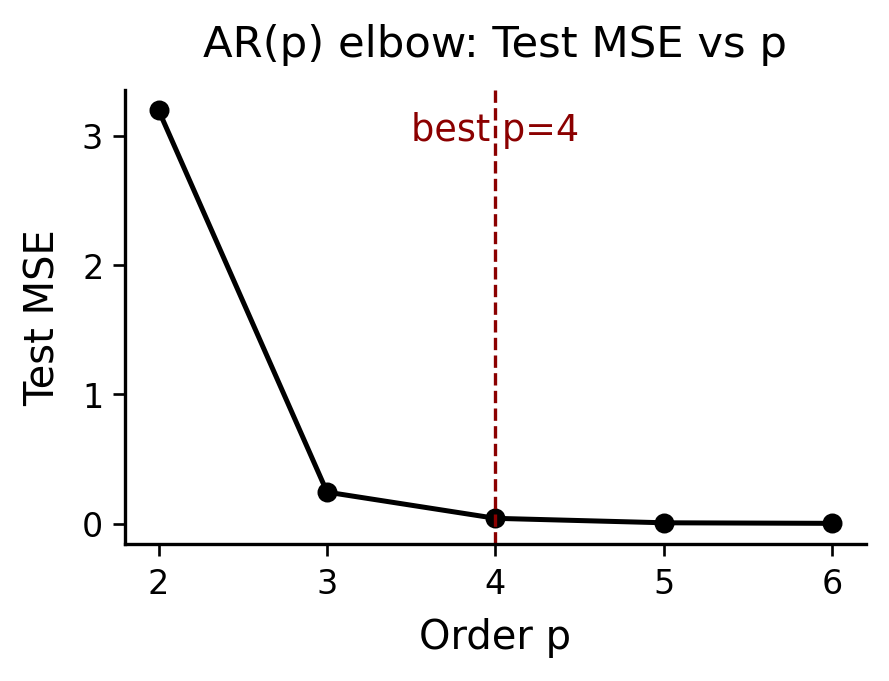

In [6]:
# Sweep AR orders for elbow plot
p_list = list(range(2, 7))
mse_te_list = []
for p in p_list:
    X, y_temp = nfm.embedding.lag_matrix(xs, order=p)
    ntr_temp = int(0.9 * len(y_temp))
    X_tr, y_tr = X[:ntr_temp], y_temp[:ntr_temp]
    X_te, y_te = X[ntr_temp:], y_temp[ntr_temp:]
    _ar_fit = nfm.models.AR(order=p).fit(xs[:p + ntr_temp])
    w_temp = np.r_[_ar_fit.intercept, _ar_fit.coefficients]
    yhat_te = (np.column_stack([np.ones(len(X_te)), X_te]) @ w_temp)
    _metrics = nfm.models.prediction_metrics(y_te, yhat_te)
    (mse_te, _, _) = _metrics.mse, _metrics.mae, _metrics.correlation
    mse_te_list.append(mse_te)

best_p_by_mse = p_list[int(np.argmin(mse_te_list))]

def plot_mse_elbow(p_list, mse_list, best_p, color_main="black", color_alt="darkred"):
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(p_list, mse_list, marker='o', color=color_main, lw=1.5, ms=5)
    ax.axvline(best_p, linestyle='--', color=color_alt, linewidth=1)
    ax.text(best_p, ax.get_ylim()[1]*0.95, f"best p={best_p}", ha='center', va='top', color=color_alt, fontsize=11)
    sf = ScalarFormatter(useMathText=True)
    sf.set_powerlimits((-3, 3))
    ax.yaxis.set_major_formatter(sf)
    ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3))
    ax.yaxis.get_offset_text().set_size(10)
    nfm.plotting.prettify(ax, title="AR(p) elbow: Test MSE vs p", xlabel="Order p", ylabel="Test MSE")
    plt.tight_layout()
    plt.show()

plot_mse_elbow(p_list, mse_te_list, 4)

## 6. Fit the Model and Reconstruct the Held-Out Interval

The main example fits **AR(4)** on the initial **90%** of
available target rows and evaluates on the later **10%**. The
coefficients remain fixed after fitting; they are not re-estimated
as the test trace advances.

Unlike the order sweep, this step uses a **recursive forecast with
observed-history refreshes every 5 samples** (10 ms at
500 Hz). At each refresh the predictor receives the actual preceding
lag values. Within that block, it feeds its predictions back into
the model. This tests short stretches of model evolution while
limiting accumulated drift. It is neither an uninterrupted free run
nor a one-step prediction at every sample.

`true_test` and `yhat_ctrl` are aligned observed and predicted test
arrays. The printed MSE measures squared amplitude error, while the
correlation measures waveform covariation. Their protocol differs
from the one-step order curve, so they need not have the same error.
`xs_pred_full` additionally reconstructs the complete processed
interval for visualization; its initial model history is copied from
the recording.


In [7]:
ar_results = fit_ar_model(xs, Fs, p=4, train_frac=0.9, refresh_every=5)

w = ar_results['w']
p_use = ar_results['p']
ntr = ar_results['ntr']
y = ar_results['y']
true_test = ar_results['true_test']
yhat_ctrl = ar_results['yhat_ctrl']
xs_pred_full = ar_results['xs_pred_full']
REFRESH_EVERY = ar_results['refresh_every']

print(f"AR({p_use}): MSE={ar_results['mse']:.6f}, corr={ar_results['corr']:.3f}")

AR(4): MSE=23.665544, corr=0.995


### Interpret the Fitted Coefficients

Each bar is the coefficient multiplying one lagged sample. Positive
coefficients reinforce that sample's contribution; negative coefficients
subtract it. Together, these weights can describe oscillation, decay,
or a mixture of temporal patterns. The intercept is not included in
this bar plot.

Read the coefficients as a group rather than treating a large bar as
a separate oscillation. Neighboring samples of a filtered signal can
be highly correlated, so large positive and negative coefficients may
partly cancel. Oscillatory modes are associated with complex-conjugate
poles of the fitted AR model, not individual coefficients. The pole
analysis in the [dimensionality tutorial](intrinsic_extrinsic.ipynb)
develops that connection.


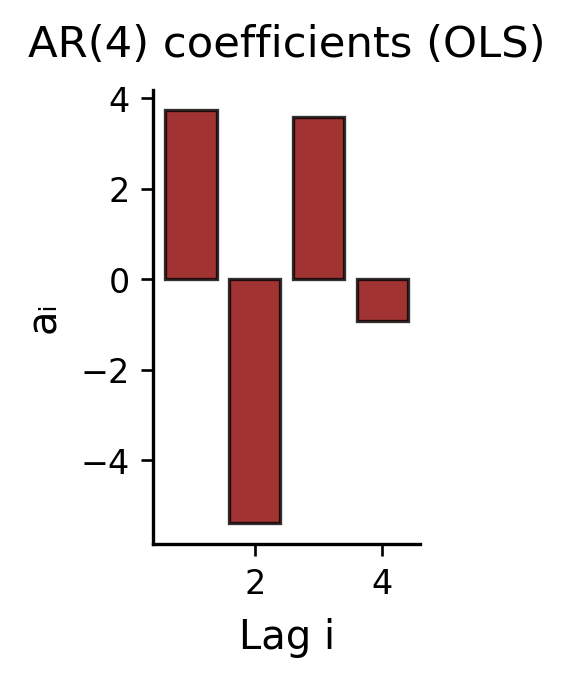

In [8]:
def plot_ar_coefficients(w, p, color_main="black", color_alt="darkred"):
    fig, ax = plt.subplots(figsize=(2, 3))
    ax.bar(np.arange(1, p+1), w[1:], color=color_alt, edgecolor=color_main, alpha=0.8)
    nfm.plotting.prettify(ax, title=f"AR({p}) coefficients (OLS)", xlabel="Lag i", ylabel="aᵢ")
    plt.tight_layout()
    plt.show()

plot_ar_coefficients(w, p_use)

## 7. Compare the Reconstructed and Observed Waveforms

The overlay shows whether the fitted model follows the timing and shape
of the processed recording. Between history refreshes, each prediction
becomes an input to the next prediction. Errors can therefore accumulate
within a block even though the model is periodically re-anchored to
observed data.

The prediction function below adds **1 to the observed trace for display**
and leaves the prediction unshifted. That vertical separation is a plotting
offset, not an estimated bias. Compare peaks, troughs, and temporal
alignment here; use the residual and scatter plots for amplitude error.
The horizontal axis is the test-sample index, so dividing by `Fs` gives
elapsed seconds within the test interval.

Accurate short-horizon reconstruction is useful evidence that the AR
model captures local dependence. It does not yet establish that an
autonomous simulation would reproduce the signal's longer-term geometry.


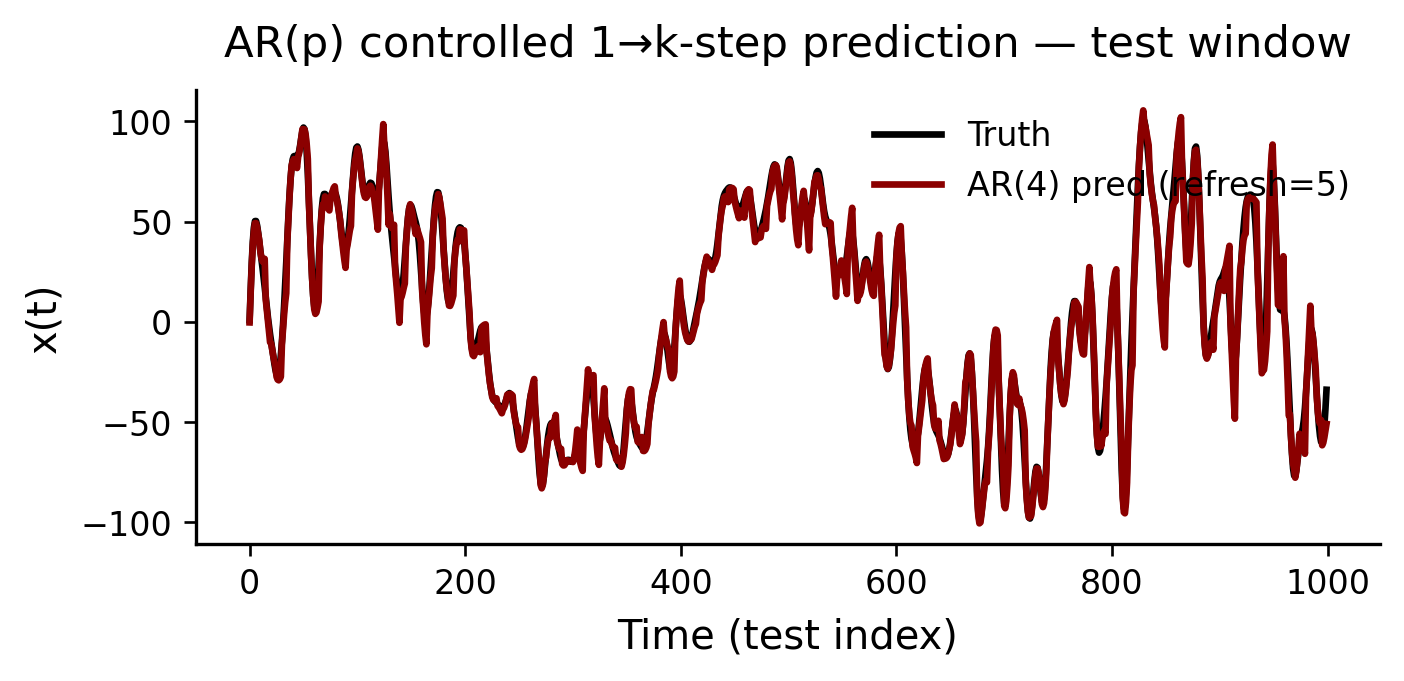

In [9]:
def plot_prediction(y_true, y_pred, p, refresh, color_main="black", color_alt="darkred"):
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(y_true + 1, color=color_main, lw=2, label="Truth")
    ax.plot(y_pred, color=color_alt, lw=2, label=f"AR({p}) pred (refresh={refresh})")
    nfm.plotting.prettify(ax, title="AR(p) controlled 1→k-step prediction — test window", xlabel="Time (test index)", ylabel="x(t)", add_legend=True)
    plt.tight_layout()
    plt.show()

plot_prediction(y[ntr:], yhat_ctrl, p_use, REFRESH_EVERY)

### Examine What the Model Leaves Unexplained

A residual is the observed value minus its prediction:

$$e(t)=x(t)-\widehat{x}(t).$$

The residual autocorrelation function (ACF) asks whether errors separated
by a given number of samples still vary together. Lag zero is always 1.
Repeated structure at nonzero lags means that the reconstructed waveform
leaves temporal dependence unexplained; an oscillating ACF can reveal
a residual rhythmic component that is not obvious in a small waveform
overlay. Convert an ACF lag to seconds by dividing it by `Fs`.

The dashed lines are the familiar white-noise reference
$\pm1.96/\sqrt{N}$, where $N$ is the number of residuals. They are an
approximate pointwise guide, not simultaneous confidence bounds across
all lags. These residuals also come from periodically refreshed recursive
predictions rather than solely one-step innovations. Interpret the
overall ACF pattern alongside the prediction protocol, rather than
requiring every stem to lie inside the dashed lines.


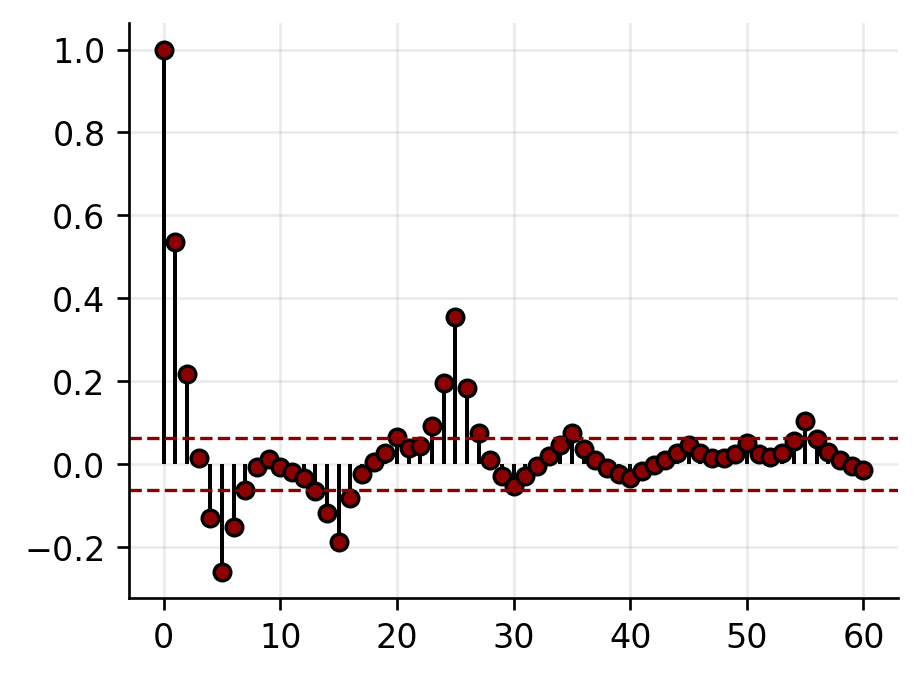

In [10]:
def plot_residual_acf(resid, nlags=60, color_main="black", color_alt="darkred"):
    acf_vals = acf(resid, nlags=nlags)
    bound = 1.96 / np.sqrt(max(len(resid), 1))
    fig, ax = plt.subplots(figsize=(4, 3))
    markerline, stemlines, baseline = ax.stem(range(len(acf_vals)), acf_vals, basefmt=" ")
    plt.setp(stemlines, color=color_main, linewidth=1.2)
    plt.setp(markerline, marker='o', markersize=5, markeredgecolor=color_main, markerfacecolor=color_alt)
    ax.axhline(bound, linestyle='--', color=color_alt, linewidth=1)
    ax.axhline(-bound, linestyle='--', color=color_alt, linewidth=1)
    plt.tight_layout()
    plt.show()

resid_te = y[ntr:] - yhat_ctrl
plot_residual_acf(resid_te)

### Separate Timing Agreement from Amplitude Agreement

In the scatter plot, each point pairs one observed test value with its
prediction at the same time. Perfect predictions lie on the identity
line. A change in slope indicates a gain mismatch, a displaced cloud
indicates an offset, and broad scatter indicates samplewise error.
Unlike the waveform overlay, the observations are not shifted here.

The two annotations describe different aspects of agreement. Pearson
correlation $\rho$ measures linear covariation and can remain high
despite a scale or offset mismatch. The coefficient of determination,

$$R^2=1-\frac{\sum_t(x(t)-\widehat{x}(t))^2}
                 {\sum_t(x(t)-\overline{x})^2},$$

compares squared error with predicting the observed test mean. It is
1 for a perfect reconstruction and can be negative when the prediction
is worse than that mean baseline. Both quantities are evaluated on
the original prediction amplitudes, before the matching used in the
geometry plots.


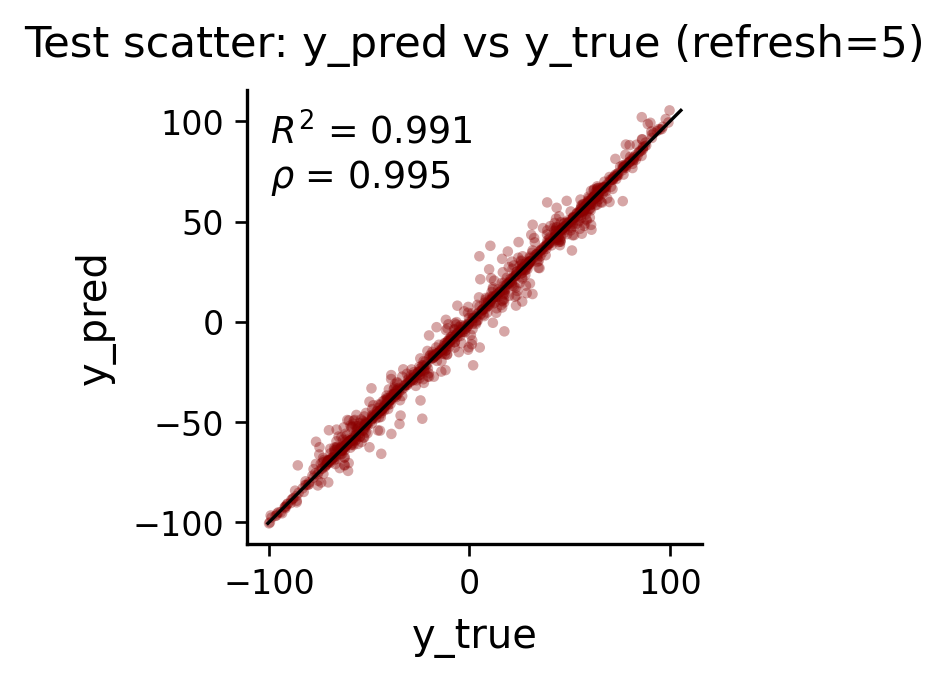

In [11]:
def plot_scatter(y_true, y_pred, refresh, color_main="black", color_alt="darkred"):
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.scatter(y_true, y_pred, c=color_alt, alpha=0.35, s=10, edgecolors="none")
    vmin, vmax = min(np.min(y_true), np.min(y_pred)), max(np.max(y_true), np.max(y_pred))
    ax.plot([vmin, vmax], [vmin, vmax], color=color_main, lw=1)
    yt = y_true - np.mean(y_true)
    yp = y_pred - np.mean(y_pred)
    corr = float((yt @ yp) / np.sqrt((yt @ yt) * (yp @ yp) + 1e-12))
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1 - ss_res / (ss_tot + 1e-12)
    ax.text(0.05, 0.95, f"$R^2$ = {r2:.3f}\n$\\rho$ = {corr:.3f}",
            transform=ax.transAxes, ha='left', va='top', fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, boxstyle="round"))
    ax.set_aspect('equal', adjustable='box')
    nfm.plotting.prettify(ax, title=f"Test scatter: y_pred vs y_true (refresh={refresh})", xlabel="y_true", ylabel="y_pred")
    plt.tight_layout()
    plt.show()

plot_scatter(y[ntr:], yhat_ctrl, REFRESH_EVERY)

## 8. Turn Temporal Relationships into a Spatial Trajectory

A delay embedding places a sample and two delayed observations in
the same three-dimensional point:

$$\mathbf{z}(t)=\left[x(t),\;x(t-\tau),\;x(t-2\tau)\right].$$

Advancing $t$ traces a curve. For a simple oscillation, delayed
coordinates represent different phases and can open a loop. Multiple
sustained oscillations can produce richer, torus-like structure when
their phases are sufficiently independent and the delays resolve
them. Noise, changing amplitudes, finite observation time, and the
choice of coordinates affect what is visible; a torus is not
guaranteed by choosing a particular AR order.

Here $m=3$ and **$\tau=30$ samples**, or **60 ms** at 500 Hz.
`nfm.embedding.delay` returns rows ordered in time with the newest
sample first. A segment of $N$ samples produces $N-2\tau$ points,
because the earliest samples do not have a complete delayed history.
The delay is supplied explicitly in this example, not selected by
an optimization routine.

Before plotting, the predicted trace is shifted and scaled to match
the test trace's mean and standard deviation. This helps compare
**shape and temporal organization separately from overall amplitude**.
It uses the observed comparison interval and is not part of the
previously reported prediction accuracy. Black is the processed
recording and dark red is the amplitude-matched, periodically refreshed
reconstruction. No torus surface is fitted in this cell.


/tmp/ipykernel_3766431/1674033388.py:30: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=2.5)


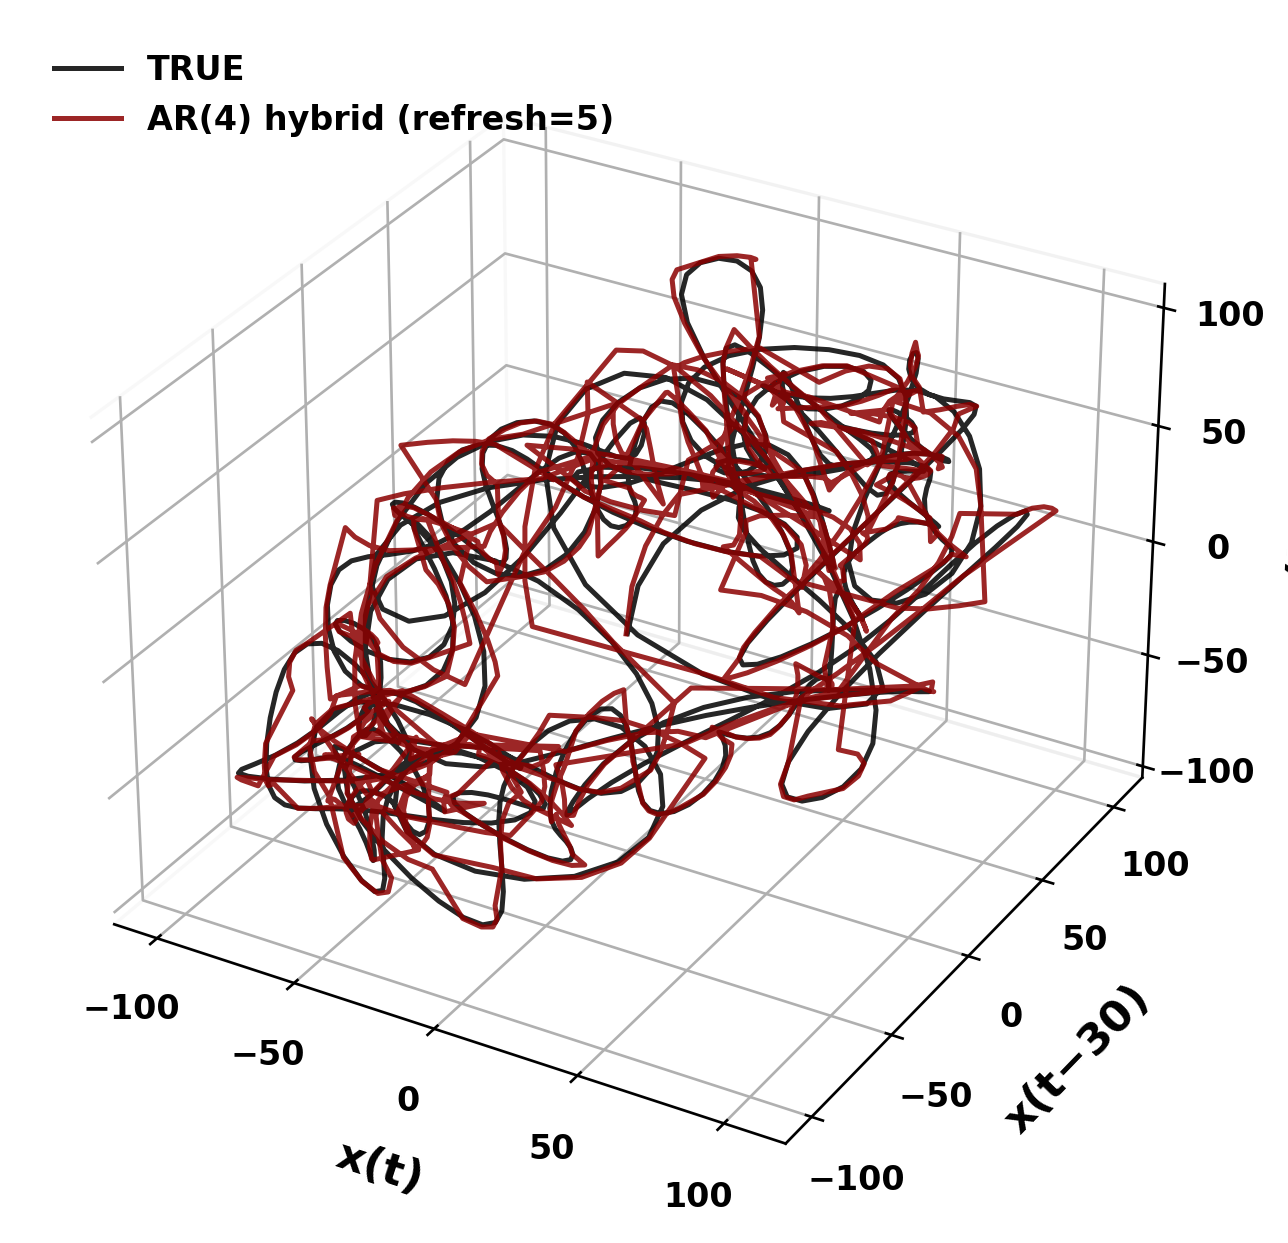

In [12]:
def plot_state_space(X3_true, X3_pred, p, tau, refresh, color_true="black", color_pred="darkred"):
    from matplotlib.ticker import MultipleLocator
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot(X3_true[:,0], X3_true[:,1], X3_true[:,2], label="TRUE", color=color_true, alpha=0.85, lw=1.5)
    ax.plot(X3_pred[:,0], X3_pred[:,1], X3_pred[:,2], label=f"AR({p}) hybrid (refresh={refresh})", color=color_pred, alpha=0.85, lw=1.5)

    # Bold axis labels (LaTeX)
    ax.set_xlabel(r"$\mathbf{x(t)}$", labelpad=8, fontsize=13)
    ax.set_ylabel(f"$\\mathbf{{x(t\\!-\\!{tau})}}$", labelpad=8, fontsize=13)
    ax.set_zlabel(f"$\\mathbf{{x(t\\!-\\!{2*tau})}}$", labelpad=8, fontsize=13)

    # Clean tick spacing: increments of 50
    ax.xaxis.set_major_locator(MultipleLocator(50))
    ax.yaxis.set_major_locator(MultipleLocator(50))
    ax.zaxis.set_major_locator(MultipleLocator(50))
    ax.tick_params(axis='both', pad=4, labelsize=10)

    # Bold tick labels
    for label in ax.xaxis.get_ticklabels() + ax.yaxis.get_ticklabels() + ax.zaxis.get_ticklabels():
        label.set_fontweight('bold')

    # Remove grey background panes
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False

    ax.legend(frameon=False, loc='upper left', fontsize=11, prop={'weight': 'bold'})
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.12, top=0.95)
    plt.tight_layout(pad=2.5)
    plt.show()

tau = 30
hy = yhat_ctrl - np.mean(yhat_ctrl)
hy = hy * (np.std(true_test) / (np.std(hy) + 1e-12)) + np.mean(true_test)

X3_true = nfm.embedding.delay(np.asarray(true_test, dtype=np.float32), dimension=3, tau_samples=tau)
X3_hyb = nfm.embedding.delay(np.asarray(hy, dtype=np.float32), dimension=3, tau_samples=tau)

plot_state_space(X3_true, X3_hyb, p_use, tau, REFRESH_EVERY)

## 9. Compare Geometry across Time Windows

A long recording can superimpose several locally different geometries.
Shorter views help distinguish a coherent local loop from the thicker
cloud produced when phase relationships or amplitudes change over time.
The next cell extracts **6-8, 8-10, 10-12, and 12-14 seconds** and embeds the observed and
reconstructed traces with the same delay in each panel.

The AR coefficients are reused; a separate model is not fitted to each
displayed interval. Each predicted segment is matched to its observed
segment's mean and standard deviation before embedding. Compare loop
opening, thickness, and relative trajectory shape, while remembering
that absolute amplitude differences have been removed for display.

These intervals lie within the coefficient-fitting portion of the
20-second example. They illustrate local reconstruction, not four
additional held-out performance measurements.


/tmp/ipykernel_3766431/2510605550.py:51: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=2.5, w_pad=1.5)


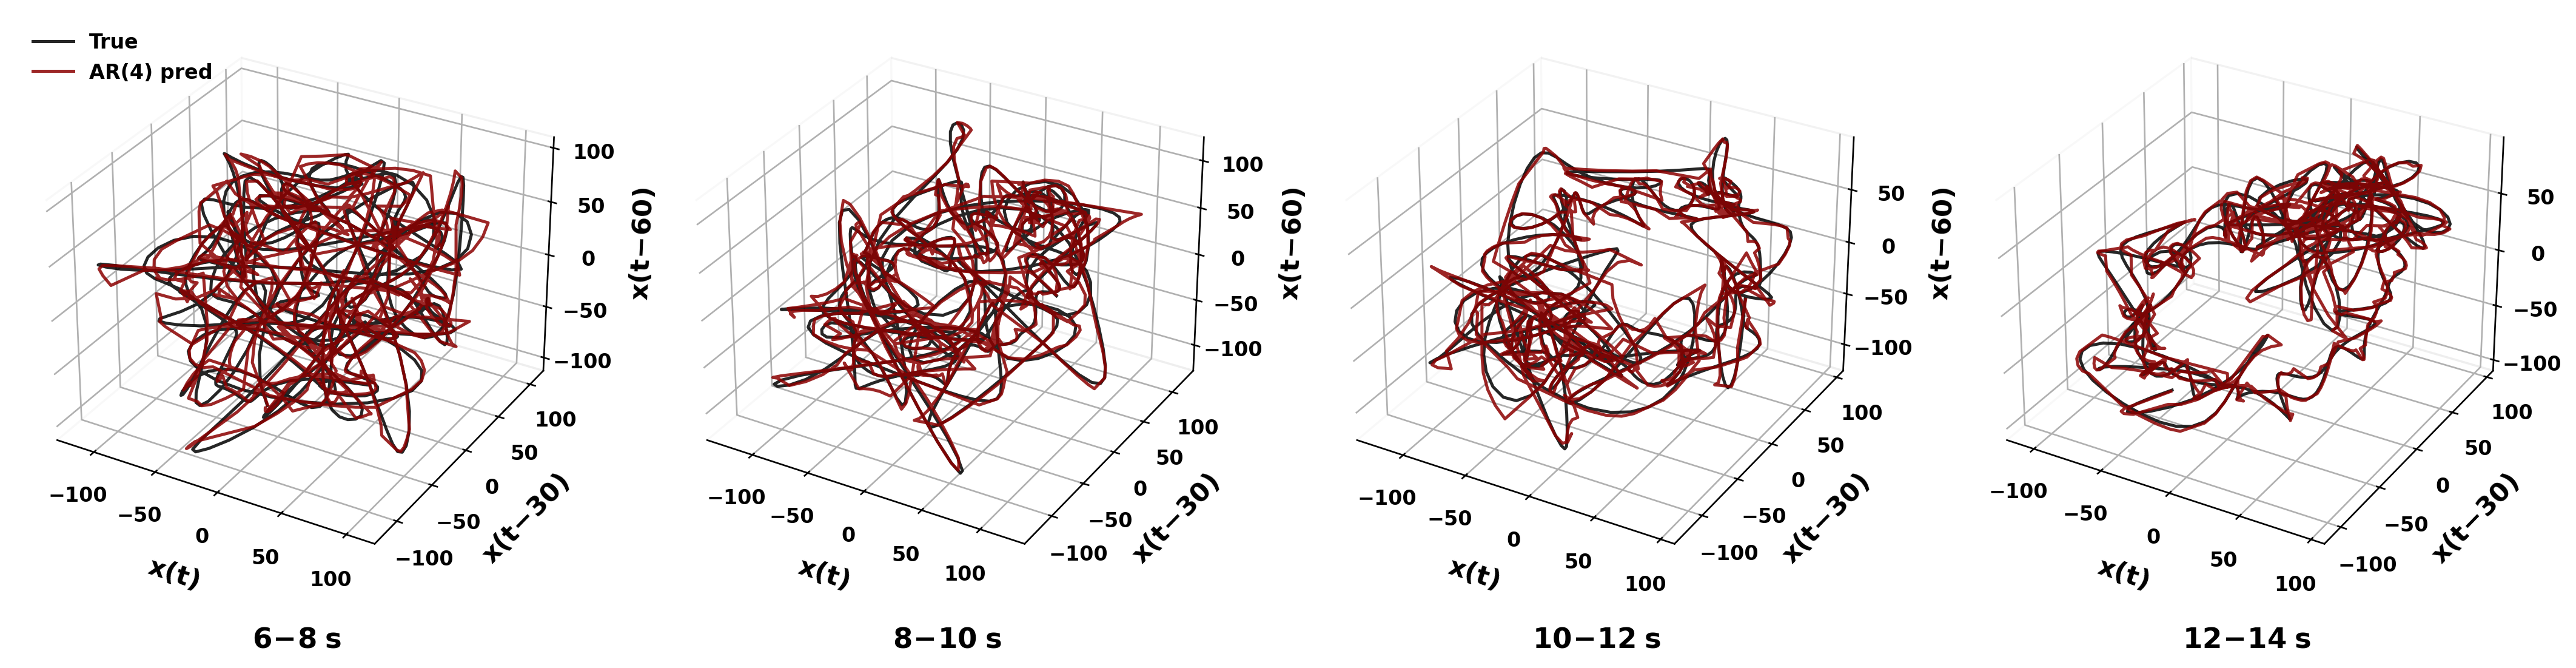

In [13]:

def plot_state_space_windows_comparison(xs, xs_pred, Fs, tau, embed_dim=3, 
                                         windows=[(6, 8), (8, 10), (10, 12), (12, 14)]):
    fig, axes = plt.subplots(1, 4, figsize=(len(windows)*4.5, 5), subplot_kw={'projection': '3d'})
    
    for ax, (t_start, t_end) in zip(axes, windows):
        idx_start = int(t_start * Fs)
        idx_end = int(t_end * Fs)
        
        # True signal
        segment_true = xs[idx_start:idx_end]
        X3_true = nfm.embedding.delay(np.asarray(segment_true, dtype=np.float32), dimension=embed_dim, tau_samples=tau)
        
        # Predicted signal (variance-matched)
        segment_pred = xs_pred[idx_start:idx_end]
        seg_pred_matched = segment_pred - np.mean(segment_pred)
        seg_pred_matched = seg_pred_matched * (np.std(segment_true) / (np.std(seg_pred_matched) + 1e-12))
        seg_pred_matched = seg_pred_matched + np.mean(segment_true)
        X3_pred = nfm.embedding.delay(np.asarray(seg_pred_matched, dtype=np.float32), dimension=embed_dim, tau_samples=tau)
        
        ax.plot(X3_true[:, 0], X3_true[:, 1], X3_true[:, 2], color='black', alpha=0.85, lw=1.5, label='True')
        ax.plot(X3_pred[:, 0], X3_pred[:, 1], X3_pred[:, 2], color='darkred', alpha=0.85, lw=1.5, label='AR(4) pred')
        
        # Bold axis labels (LaTeX)
        ax.set_xlabel(r"$\mathbf{x(t)}$", labelpad=8, fontsize=13)
        ax.set_ylabel(f"$\\mathbf{{x(t\\!-\\!{tau})}}$", labelpad=8, fontsize=13)
        ax.set_zlabel(f"$\\mathbf{{x(t\\!-\\!{2*tau})}}$", labelpad=8, fontsize=13)
        
        # Clean tick spacing: increments of 50
        from matplotlib.ticker import MultipleLocator
        ax.xaxis.set_major_locator(MultipleLocator(50))
        ax.yaxis.set_major_locator(MultipleLocator(50))
        ax.zaxis.set_major_locator(MultipleLocator(50))
        ax.tick_params(axis='both', pad=4, labelsize=10)
        
        # Bold tick labels
        for label in ax.xaxis.get_ticklabels() + ax.yaxis.get_ticklabels() + ax.zaxis.get_ticklabels():
            label.set_fontweight('bold')
        
        # Remove grey background panes
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        
        # Bold time-window annotation
        ax.text2D(0.5, -0.12, f"$\\mathbf{{{t_start}\\!-\\!{t_end} \\; s}}$",
                  transform=ax.transAxes, ha='center', fontsize=14, fontweight='bold')
    
    axes[0].legend(frameon=False, loc='upper left', fontsize=11,
                   prop={'weight': 'bold'})
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.12, top=0.95, wspace=0.15)
    plt.tight_layout(pad=2.5, w_pad=1.5)
    plt.savefig("1.pdf", bbox_inches='tight', dpi=300)
    plt.show()

# Build full prediction for visualization
full_pred = nfm.models.ARFit(w[0], w[1:]).forecast(xs, start_sample=p_use, n_samples=len(xs)-p_use, refresh_samples=REFRESH_EVERY)
xs_pred_full = np.concatenate([xs[:p_use], full_pred])

plot_state_space_windows_comparison(xs, xs_pred_full, Fs, tau)


## 10. Inspect Sensitivity to the Embedding Delay

The next comparison holds the signal interval and fitted model fixed
and changes only the coordinate delay. It uses **18-20 seconds**, with
$\tau$ equal to **3, 30, 60, and 90 samples**: **6, 60, 120, and 180 ms** at 500 Hz.

When a delay is very small relative to the oscillatory timescale,
adjacent coordinates are nearly identical, compressing the curve
toward a diagonal. A larger delay can separate phases and reveal an
opening. Still larger delays can alter the apparent shape, mix
changing dynamics across a longer history, or align particular
oscillations unfavorably. Larger is therefore not automatically better.

Each three-dimensional point spans $2\tau$ samples of history, and
the number of points decreases as the delay increases. Judge the
displayed differences as changes of representation, not changes to
the underlying recording or additional fitted models. A useful delay
resolves the relevant temporal structure and remains interpretable
across nearby choices and time windows; an attractive isolated view
alone is not a topology estimate.


/tmp/ipykernel_3766431/1002882034.py:49: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=2.5, w_pad=1.5)


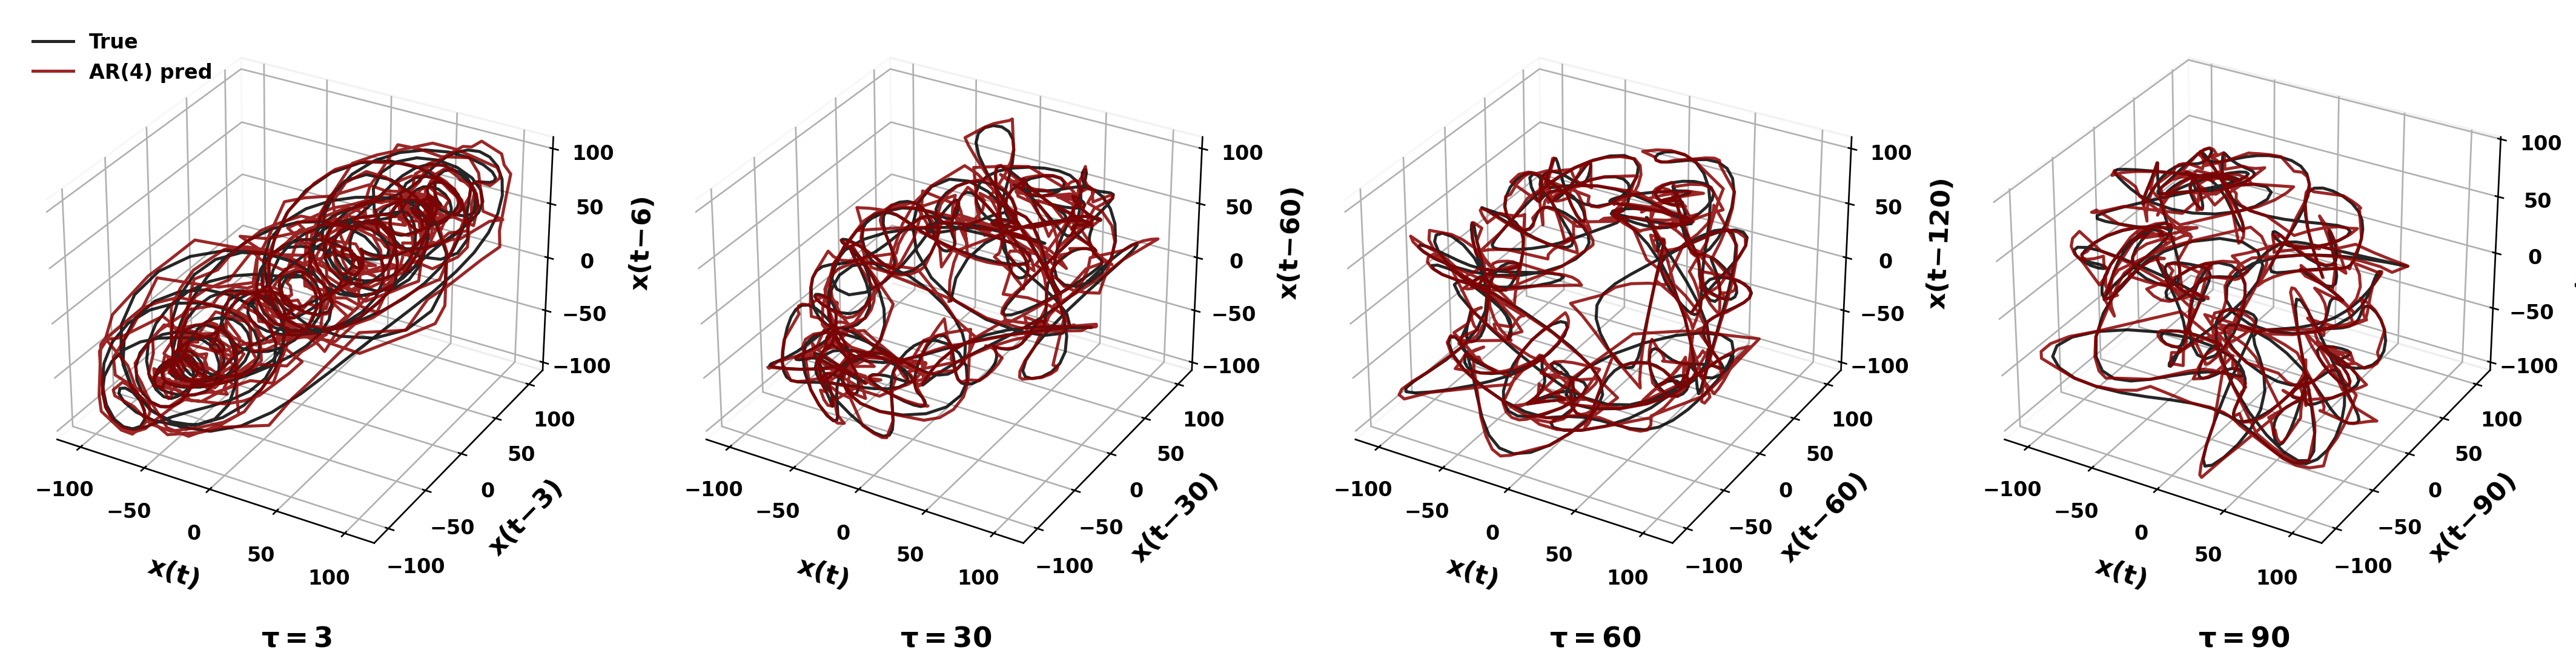

In [14]:

def plot_state_space_tau_sweep(xs, xs_pred, Fs, t_start, t_end, taus=[3, 30, 60, 90], embed_dim=3):
    from matplotlib.ticker import MultipleLocator
    fig, axes = plt.subplots(1, 4, figsize=(18, 5), subplot_kw={'projection': '3d'})
    
    idx_start = int(t_start * Fs)
    idx_end = int(t_end * Fs)
    segment_true = xs[idx_start:idx_end]
    segment_pred = xs_pred[idx_start:idx_end]
    
    # Variance-match prediction
    seg_pred_matched = segment_pred - np.mean(segment_pred)
    seg_pred_matched = seg_pred_matched * (np.std(segment_true) / (np.std(seg_pred_matched) + 1e-12))
    seg_pred_matched = seg_pred_matched + np.mean(segment_true)

    for ax, tau_val in zip(axes, taus):
        X3_true = nfm.embedding.delay(np.asarray(segment_true, dtype=np.float32), dimension=embed_dim, tau_samples=tau_val)
        X3_pred = nfm.embedding.delay(np.asarray(seg_pred_matched, dtype=np.float32), dimension=embed_dim, tau_samples=tau_val)
        
        ax.plot(X3_true[:, 0], X3_true[:, 1], X3_true[:, 2], color='black', alpha=0.85, lw=1.5, label='True')
        ax.plot(X3_pred[:, 0], X3_pred[:, 1], X3_pred[:, 2], color='darkred', alpha=0.85, lw=1.5, label='AR(4) pred')
        
        # Bold axis labels (LaTeX)
        ax.set_xlabel(r"$\mathbf{x(t)}$", labelpad=8, fontsize=13)
        ax.set_ylabel(f"$\\mathbf{{x(t\\!-\\!{tau_val})}}$", labelpad=8, fontsize=13)
        ax.set_zlabel(f"$\\mathbf{{x(t\\!-\\!{2*tau_val})}}$", labelpad=8, fontsize=13)
        
        # Clean tick spacing: increments of 50
        ax.xaxis.set_major_locator(MultipleLocator(50))
        ax.yaxis.set_major_locator(MultipleLocator(50))
        ax.zaxis.set_major_locator(MultipleLocator(50))
        ax.tick_params(axis='both', pad=4, labelsize=10)
        
        # Bold tick labels
        for label in ax.xaxis.get_ticklabels() + ax.yaxis.get_ticklabels() + ax.zaxis.get_ticklabels():
            label.set_fontweight('bold')
        
        # Remove grey background panes
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        
        # Bold tau annotation
        ax.text2D(0.5, -0.12, f"$\\mathbf{{\\tau = {tau_val}}}$",
                  transform=ax.transAxes, ha='center', fontsize=14, fontweight='bold')
    
    axes[0].legend(frameon=False, loc='upper left', fontsize=11,
                   prop={'weight': 'bold'})
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.12, top=0.95, wspace=0.15)
    plt.tight_layout(pad=2.5, w_pad=1.5)
    plt.savefig("2.pdf", bbox_inches='tight', dpi=300)
    plt.show()

plot_state_space_tau_sweep(xs, xs_pred_full, Fs, t_start=18, t_end=20)


## 11. Reconstruct Individual Recording Channels

The final comparison repeats preprocessing and AR fitting separately
for several channels. Each predictor uses only the history of its own
channel. Signals are not averaged across electrodes, and a model
trained on one channel is not used to predict another. This distinguishes
a collection of univariate reconstructions from a multivariate model.

The four examples use channels **1001-1004**, delays of **30 samples**,
and display intervals **18-20, 18-20, 10-12, and 18-20 seconds**,
respectively. Each channel is processed at 1-50 Hz and fitted with
AR(4), a 90% training fraction, and five-sample history refreshes.
The fitting segment extends from the recording start to 100 samples
beyond the displayed endpoint, so its total duration varies with
that endpoint. Do not assume every plotted point is held out.

Compare the observed and reconstructed trajectory within each panel
first, then look for recurring geometry across panels. Each prediction
is amplitude-matched to its corresponding observed interval. Since
the displayed times can differ and neighboring electrodes can share
activity, these panels are illustrative comparisons, not independent
evidence of distinct sources or a cross-channel prediction benchmark.


/tmp/ipykernel_3766431/985238697.py:78: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=2.5, w_pad=1.5)


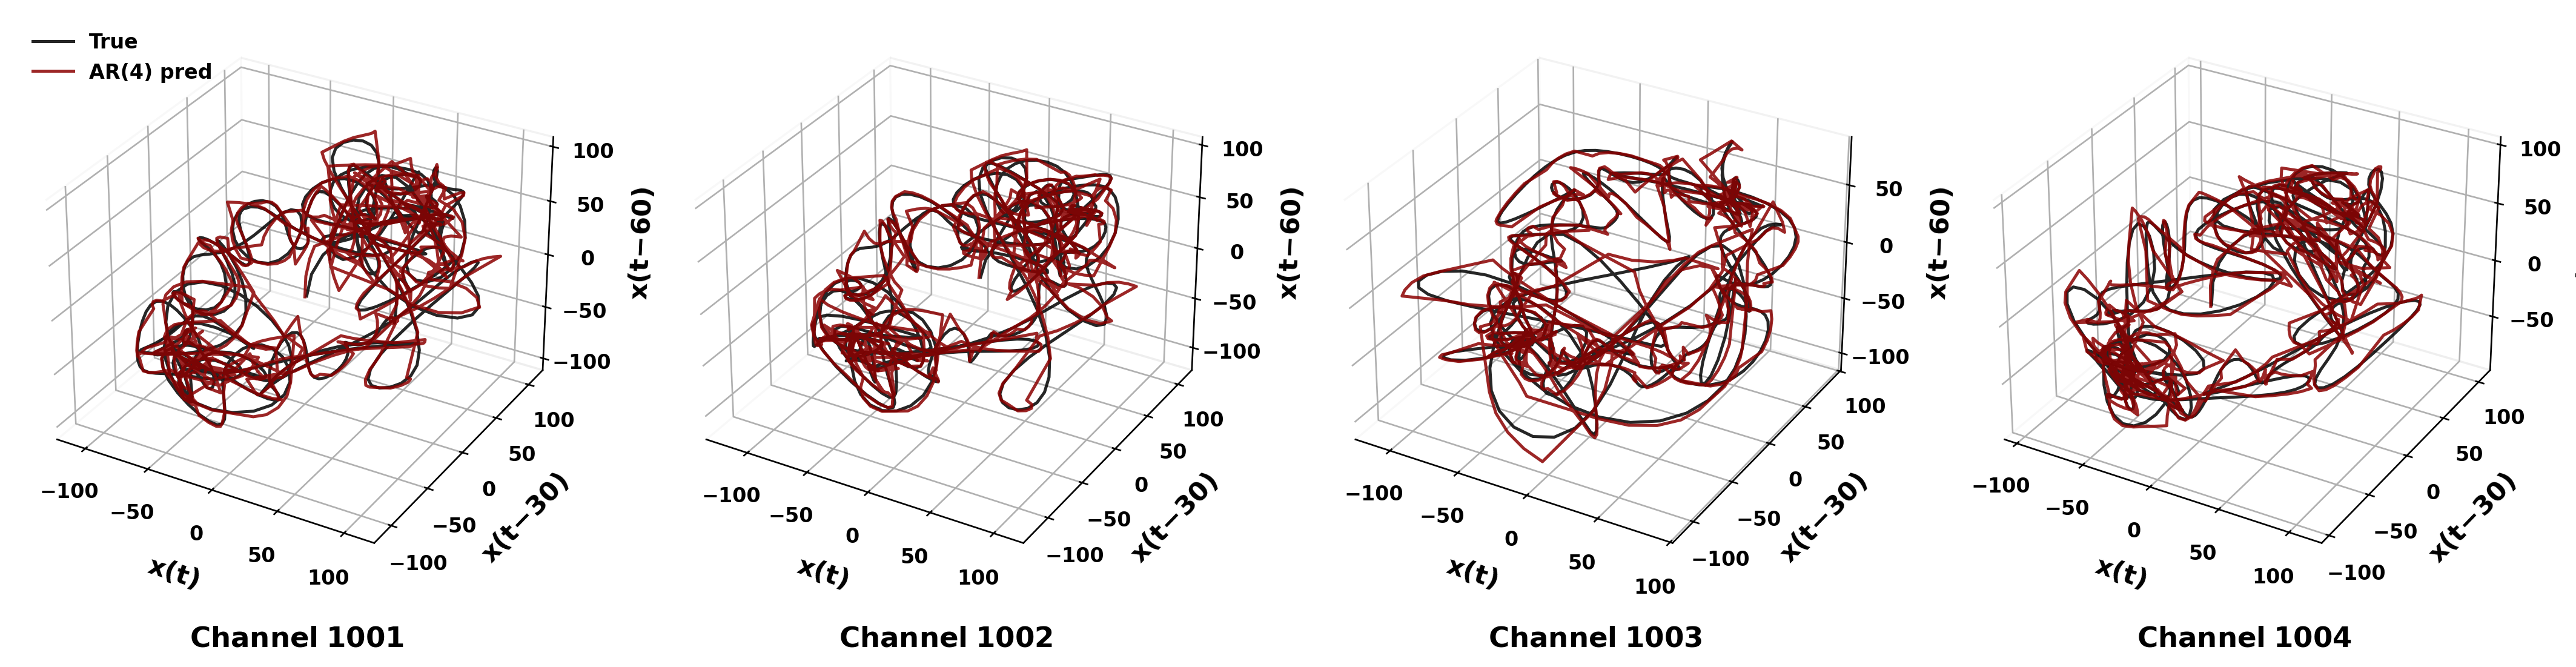

In [15]:
def sweep_channels_plot(LFP, channels, time_windows, taus, Fs, 
                        p=4, train_frac=0.9, refresh_every=5,
                        bandpass_low=1.0, bandpass_high=50.0, fband=(1, 80), env_lp_hz=3.0,
                        embed_dim=3):
    """
    Process multiple channels and plot state space comparison.
    
    Parameters
    ----------
    channels : list of int
        Channel indices to process
    time_windows : list of tuple
        (start_sec, end_sec) for each channel's plot window
    taus : list of int
        Embedding delay for each channel
    """
    from matplotlib.ticker import MultipleLocator
    n = len(channels)
    fig, axes = plt.subplots(1, n, figsize=(n*4.5, 5), subplot_kw={'projection': '3d'})
    if n == 1:
        axes = [axes]
    
    for ax, chan, (t_start, t_end), tau in zip(axes, channels, time_windows, taus):
        # Process full signal for this channel
        xs, _ = process_signal(LFP, chan, Fs, np.arange(int(t_end * Fs) + 100),
                               bandpass_low=bandpass_low, bandpass_high=bandpass_high,
                               fband=fband, env_lp_hz=env_lp_hz)
        
        # Fit AR model
        ar_res = fit_ar_model(xs, Fs, p=p, train_frac=train_frac, refresh_every=refresh_every)
        w, xs_pred_full = ar_res['w'], ar_res['xs_pred_full']
        
        # Extract window
        idx_start, idx_end = int(t_start * Fs), int(t_end * Fs)
        segment_true = xs[idx_start:idx_end]
        segment_pred = xs_pred_full[idx_start:idx_end]
        
        # Variance-match prediction
        seg_pred_matched = segment_pred - np.mean(segment_pred)
        seg_pred_matched = seg_pred_matched * (np.std(segment_true) / (np.std(seg_pred_matched) + 1e-12))
        seg_pred_matched = seg_pred_matched + np.mean(segment_true)
        
        # Embed
        X3_true = nfm.embedding.delay(np.asarray(segment_true, dtype=np.float32), dimension=embed_dim, tau_samples=tau)
        X3_pred = nfm.embedding.delay(np.asarray(seg_pred_matched, dtype=np.float32), dimension=embed_dim, tau_samples=tau)
        
        # Plot
        ax.plot(X3_true[:, 0], X3_true[:, 1], X3_true[:, 2], color='black', alpha=0.85, lw=1.5, label='True')
        ax.plot(X3_pred[:, 0], X3_pred[:, 1], X3_pred[:, 2], color='darkred', alpha=0.85, lw=1.5, label=f'AR({p}) pred')
        
        # Bold axis labels (LaTeX)
        ax.set_xlabel(r"$\mathbf{x(t)}$", labelpad=8, fontsize=13)
        ax.set_ylabel(f"$\\mathbf{{x(t\\!-\\!{tau})}}$", labelpad=8, fontsize=13)
        ax.set_zlabel(f"$\\mathbf{{x(t\\!-\\!{2*tau})}}$", labelpad=8, fontsize=13)
        
        # Clean tick spacing: increments of 50
        ax.xaxis.set_major_locator(MultipleLocator(50))
        ax.yaxis.set_major_locator(MultipleLocator(50))
        ax.zaxis.set_major_locator(MultipleLocator(50))
        ax.tick_params(axis='both', pad=4, labelsize=10)
        
        # Bold tick labels
        for label in ax.xaxis.get_ticklabels() + ax.yaxis.get_ticklabels() + ax.zaxis.get_ticklabels():
            label.set_fontweight('bold')
        
        # Remove grey background panes
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        
        # Bold channel annotation
        ax.text2D(0.5, -0.12, f"$\\mathbf{{Channel \\; {chan}}}$",
                  transform=ax.transAxes, ha='center', fontsize=14, fontweight='bold')
    
    axes[0].legend(frameon=False, loc='upper left', fontsize=11,
                   prop={'weight': 'bold'})
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.12, top=0.95, wspace=0.15)
    plt.tight_layout(pad=2.5, w_pad=1.5)
    plt.savefig("3.pdf", bbox_inches='tight', dpi=300)
    plt.show()
    
sweep_channels_plot(
    LFP, 
    channels=[1001, 1002, 1003, 1004],
    time_windows=[(18, 20), (18, 20), (10, 12), (18, 20)],
    taus=[30, 30, 30, 30],
    Fs=Fs
)


## 12. What to Take from the Reconstruction

This example connects a **1-50 Hz processed waveform** to a fitted
**AR(4)** predictor and a three-dimensional delay trajectory.
The waveform, residual ACF, scatter plot, and state-space views
answer complementary questions:

- **Waveform and scatter:** does the model reproduce sample timing
  and amplitude under the stated history-refresh protocol?
- **Residual ACF:** what temporal structure remains in its errors?
- **Delay geometry:** does the amplitude-matched reconstruction
  follow the observed local trajectory, and how does that comparison
  depend on the window and delay?
- **Channel views:** does a similar reconstruction remain useful
  for other individual traces under their displayed settings?

Use these views together. A high correlation does not establish
correct topology, and a visually open loop does not establish a
particular number of independent modes. The preprocessing is offline,
the AR coefficients are fixed within a fit, and observed-history
refreshes constrain the reconstruction. These choices define what
the figures demonstrate and how the example can be adapted.

To apply the workflow to another recording, begin with its actual
sampling rate and array orientation, choose a physiologically relevant
processing band, and keep model order, forecast horizon, and embedding
delay distinct. Compare several time intervals rather than relying
on a single visually appealing trajectory.

Continue with [Intrinsic vs. Embedding Dimensionality](intrinsic_extrinsic.ipynb)
for the connection between AR poles and oscillatory modes, or
[DeepLagField](model.ipynb) for learning time-varying coefficients
and autoregressive order.
